<a href="https://colab.research.google.com/github/balavardhansai/DSIP/blob/main/OPE_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1 Image

Image loaded successfully
Image shape: (305, 272, 3)


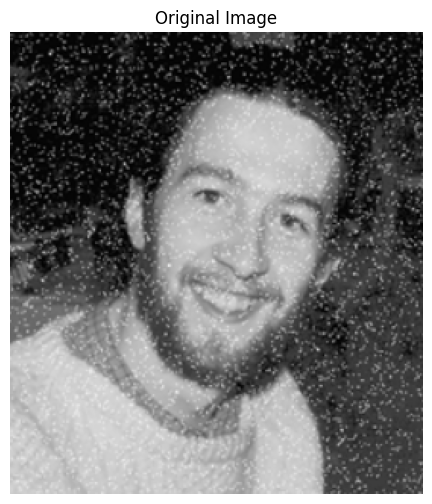

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.ndimage import generic_filter
image_path = "/content/DSIP-1.png"
img = cv2.imread(image_path)
if img is None:
    raise ValueError("Image not found. Check the image path.")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
print("Image loaded successfully")
print("Image shape:", img.shape)
plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.show()

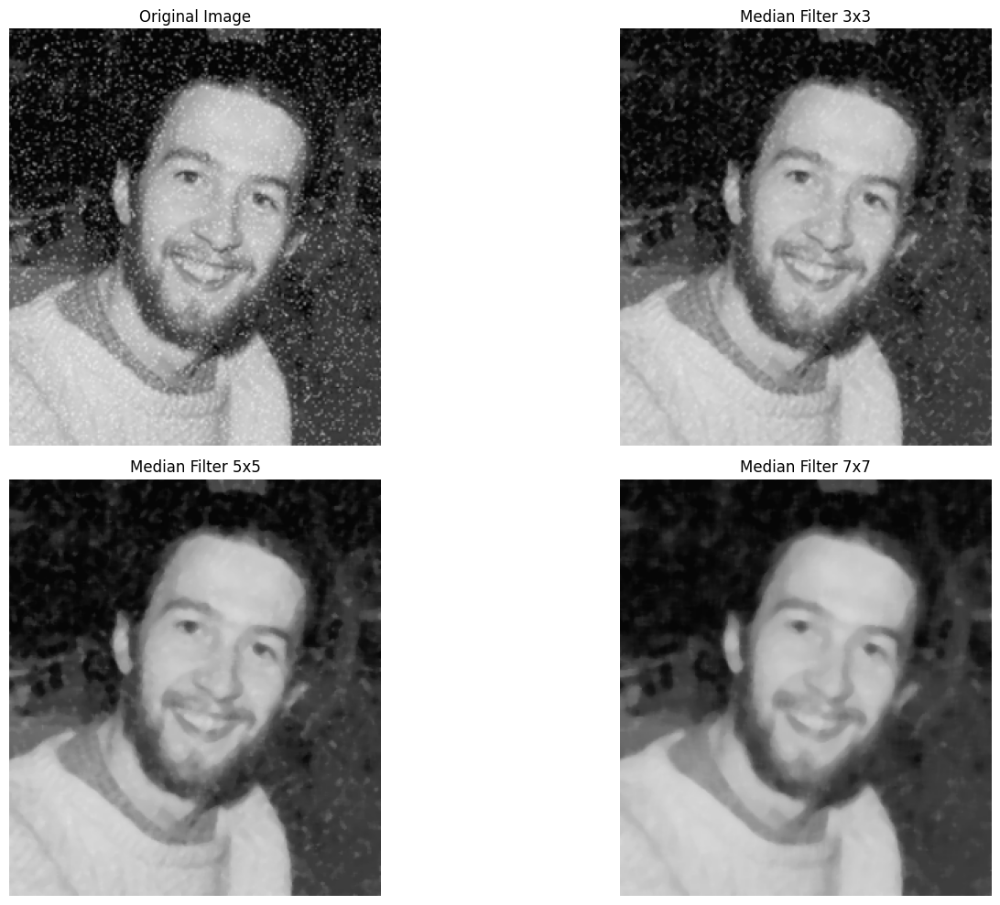

In [ ]:
median_3 = cv2.medianBlur(img, 3)
median_5 = cv2.medianBlur(img, 5)
median_7 = cv2.medianBlur(img, 7)
plt.figure(figsize=(16, 10))
plt.subplot(2, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.subplot(2, 2, 2)
plt.imshow(median_3)
plt.title("Median Filter 3x3")
plt.axis("off")
plt.subplot(2, 2, 3)
plt.imshow(median_5)
plt.title("Median Filter 5x5")
plt.axis("off")
plt.subplot(2, 2, 4)
plt.imshow(median_7)
plt.title("Median Filter 7x7")
plt.axis("off")
plt.tight_layout()
plt.show()

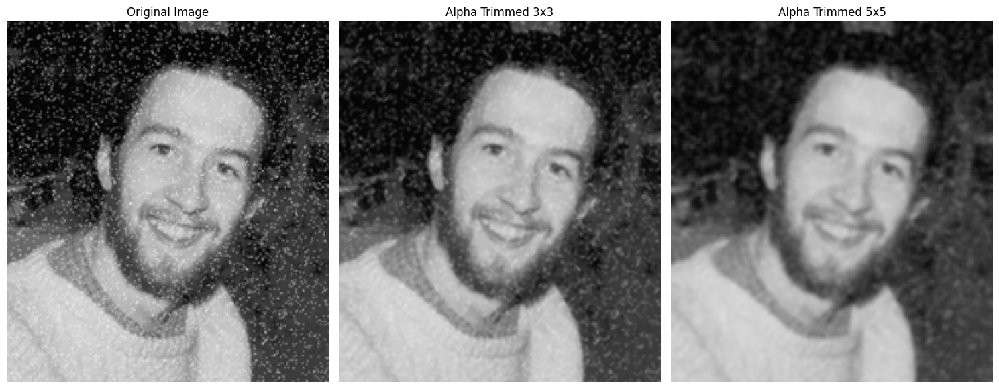

In [ ]:
def alpha_trimmed_filter(channel, size=3, d=2):
    def process(window):
        sorted_pixels = np.sort(window)
        trimmed = sorted_pixels[d//2:len(window)-d//2]
        return np.mean(trimmed)
    result = generic_filter(
        channel,
        process,
        size=size,
        mode="reflect"
    )
    return result.astype(np.uint8)
def alpha_color(image, size=3, d=2):
    channels = []
    for i in range(3):
        channels.append(
            alpha_trimmed_filter(image[:, :, i], size, d)
        )
    return np.stack(channels, axis=2)
alpha_3 = alpha_color(img, 3, 2)
alpha_5 = alpha_color(img, 5, 2)
plt.figure(figsize=(15, 6))
plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(alpha_3)
plt.title("Alpha Trimmed 3x3")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(alpha_5)
plt.title("Alpha Trimmed 5x5")
plt.axis("off")
plt.tight_layout()
plt.show()

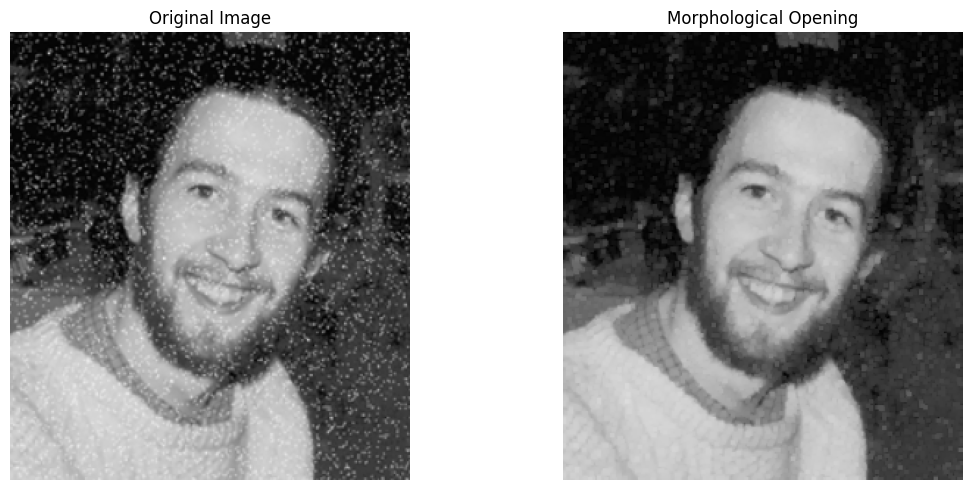

In [ ]:
kernel = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(
    img,
    cv2.MORPH_OPEN,
    kernel
)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(opening)
plt.title("Morphological Opening")
plt.axis("off")
plt.tight_layout()
plt.show()

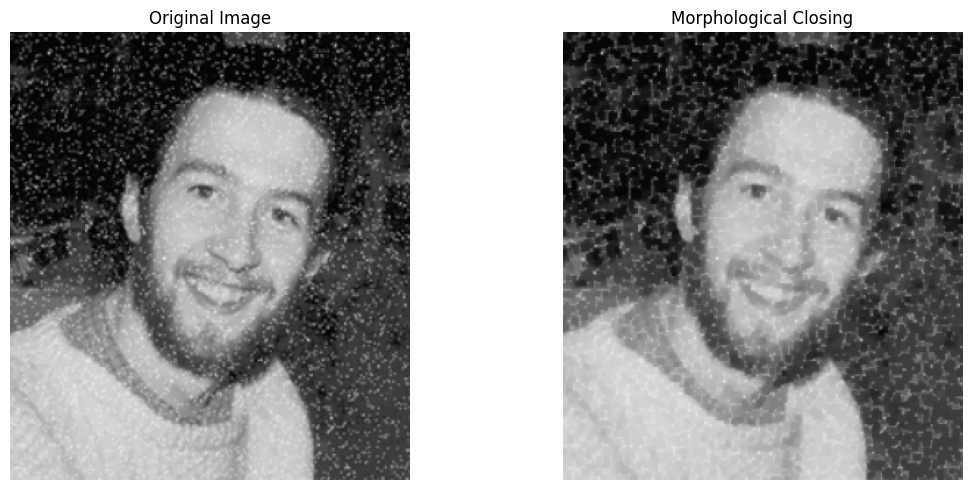

In [ ]:
kernel = np.ones((3, 3), np.uint8)
closing = cv2.morphologyEx(
    img,
    cv2.MORPH_CLOSE,
    kernel
)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(closing)
plt.title("Morphological Closing")
plt.axis("off")
plt.tight_layout()
plt.show()

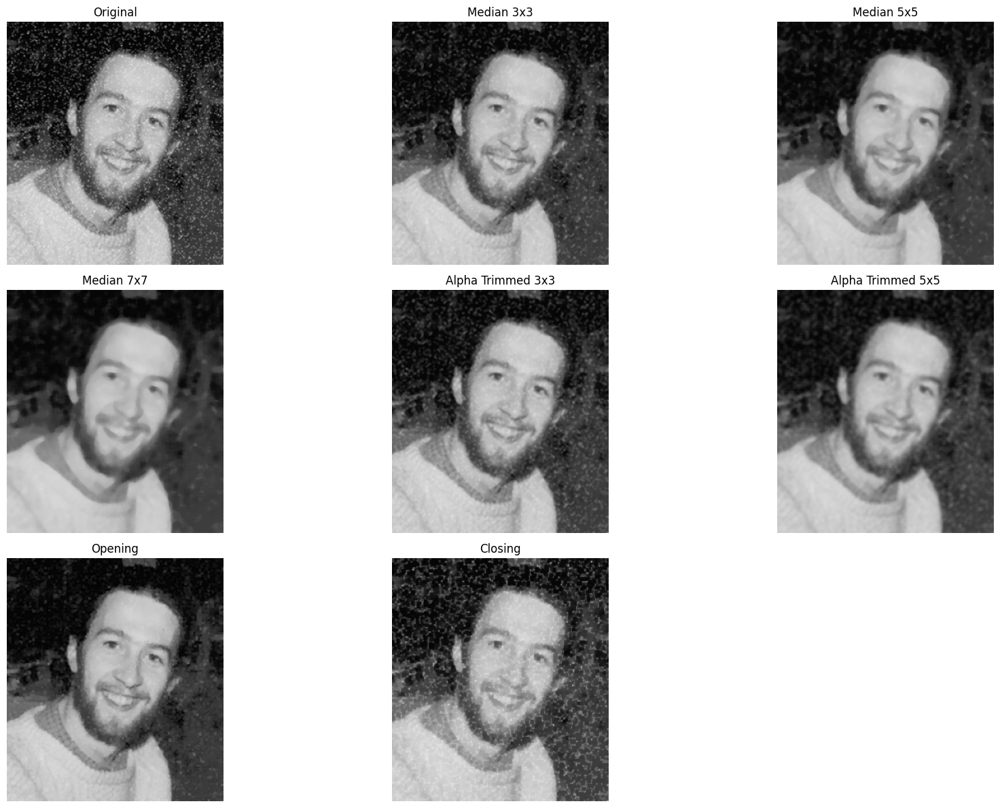

In [ ]:
results = {
    "Original": img,
    "Median 3x3": median_3,
    "Median 5x5": median_5,
    "Median 7x7": median_7,
    "Alpha Trimmed 3x3": alpha_3,
    "Alpha Trimmed 5x5": alpha_5,
    "Opening": opening,
    "Closing": closing
}
plt.figure(figsize=(18, 12))
for i, (name, image) in enumerate(results.items()):
    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(name)
    plt.axis("off")
plt.tight_layout()
plt.show()

           Filter   Sharpness
         Original 1332.654688
       Median 3x3  323.722463
       Median 5x5   83.405810
       Median 7x7   38.557722
Alpha Trimmed 3x3  131.443027
Alpha Trimmed 5x5   24.328357
          Opening  208.587458
          Closing  889.419501


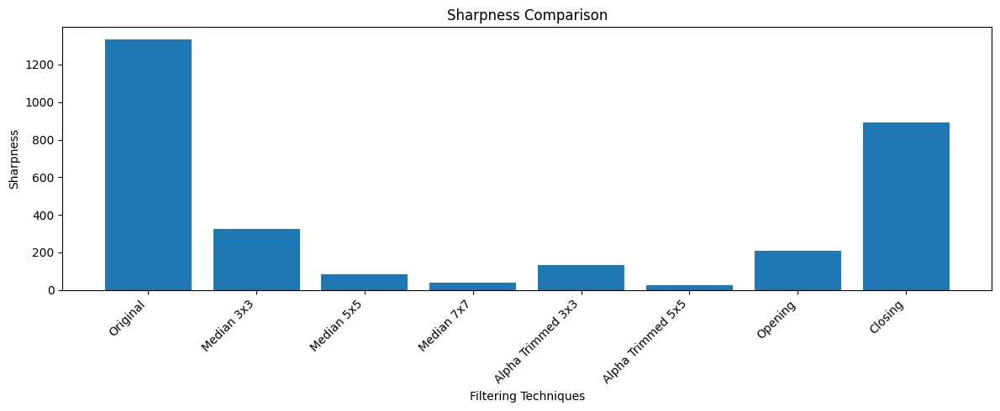

In [ ]:
sharpness_values = []
for name, image in results.items():
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    sharpness = cv2.Laplacian(
        gray,
        cv2.CV_64F
    ).var()
    sharpness_values.append([name, sharpness])
df = pd.DataFrame(
    sharpness_values,
    columns=["Filter", "Sharpness"]
)
print(df.to_string(index=False))
plt.figure(figsize=(12, 5))
plt.bar(df["Filter"], df["Sharpness"])
plt.xlabel("Filtering Techniques")
plt.ylabel("Sharpness")
plt.title("Sharpness Comparison")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

2.Image

Image loaded successfully
Image shape: (307, 211, 3)


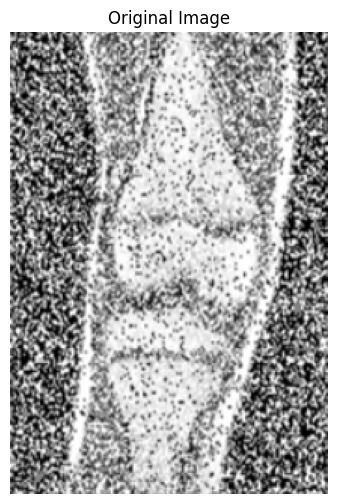

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.ndimage import generic_filter
image_path = "/content/Dsip image-2.png"
img = cv2.imread(image_path)
if img is None:
    raise ValueError("Image not found. Check the image path.")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
print("Image loaded successfully")
print("Image shape:", img.shape)
plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.show()

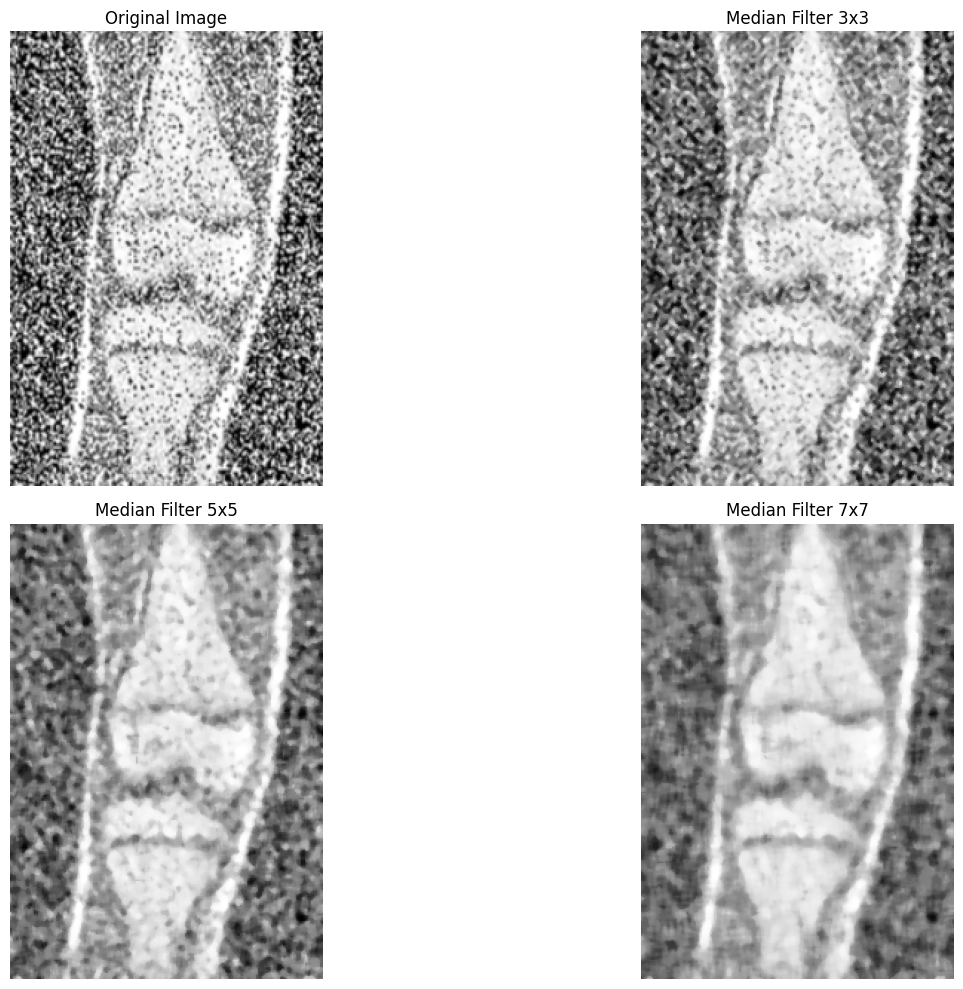

In [ ]:
median_3 = cv2.medianBlur(img, 3)
median_5 = cv2.medianBlur(img, 5)
median_7 = cv2.medianBlur(img, 7)
plt.figure(figsize=(16, 10))
plt.subplot(2, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.subplot(2, 2, 2)
plt.imshow(median_3)
plt.title("Median Filter 3x3")
plt.axis("off")
plt.subplot(2, 2, 3)
plt.imshow(median_5)
plt.title("Median Filter 5x5")
plt.axis("off")
plt.subplot(2, 2, 4)
plt.imshow(median_7)
plt.title("Median Filter 7x7")
plt.axis("off")
plt.tight_layout()
plt.show()

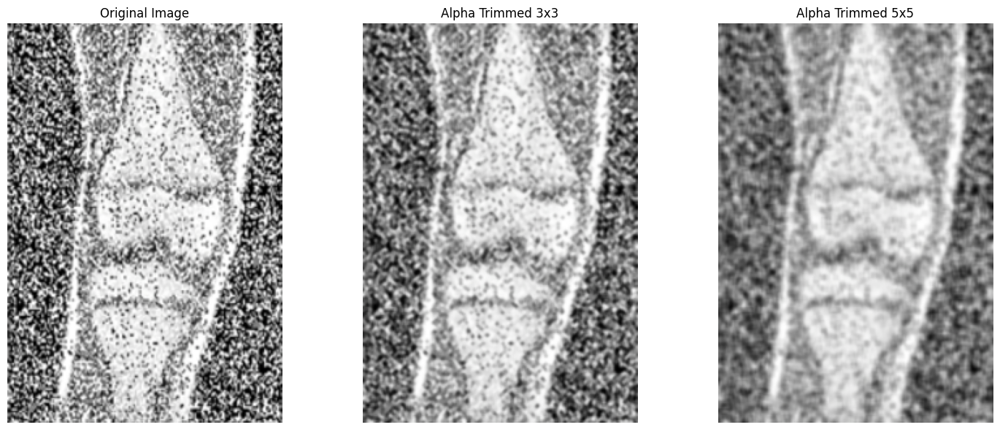

In [ ]:
def alpha_trimmed_filter(channel, size=3, d=2):
    def process(window):
        sorted_pixels = np.sort(window)
        trimmed = sorted_pixels[d//2:len(window)-d//2]
        return np.mean(trimmed)
    result = generic_filter(
        channel,
        process,
        size=size,
        mode="reflect"
    )
    return result.astype(np.uint8)
def alpha_color(image, size=3, d=2):
    channels = []
    for i in range(3):
        channels.append(
            alpha_trimmed_filter(image[:, :, i], size, d)
        )
    return np.stack(channels, axis=2)
alpha_3 = alpha_color(img, 3, 2)
alpha_5 = alpha_color(img, 5, 2)
plt.figure(figsize=(15, 6))
plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(alpha_3)
plt.title("Alpha Trimmed 3x3")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(alpha_5)
plt.title("Alpha Trimmed 5x5")
plt.axis("off")
plt.tight_layout()
plt.show()

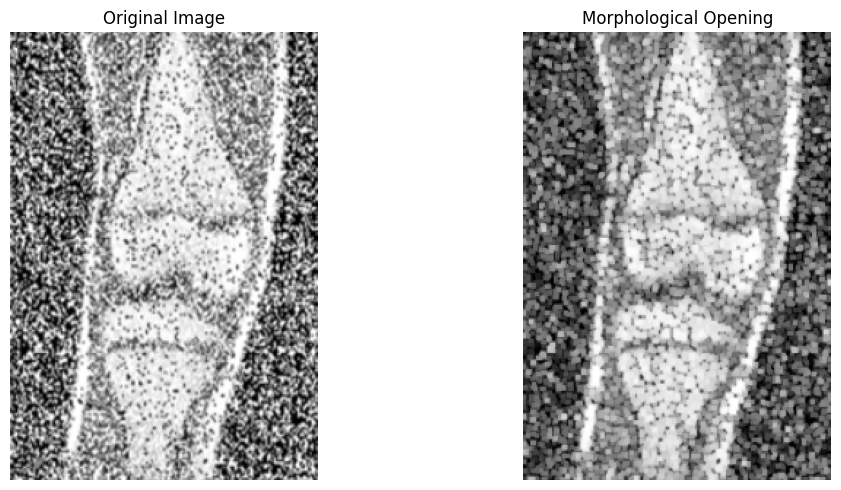

In [ ]:
kernel = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(
    img,
    cv2.MORPH_OPEN,
    kernel
)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(opening)
plt.title("Morphological Opening")
plt.axis("off")
plt.tight_layout()
plt.show()

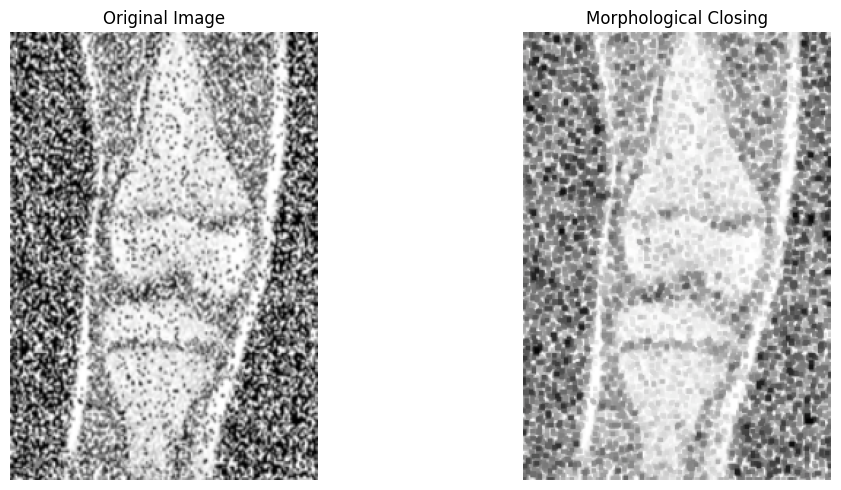

In [ ]:
kernel = np.ones((3, 3), np.uint8)
closing = cv2.morphologyEx(
    img,
    cv2.MORPH_CLOSE,
    kernel
)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(closing)
plt.title("Morphological Closing")
plt.axis("off")
plt.tight_layout()
plt.show()

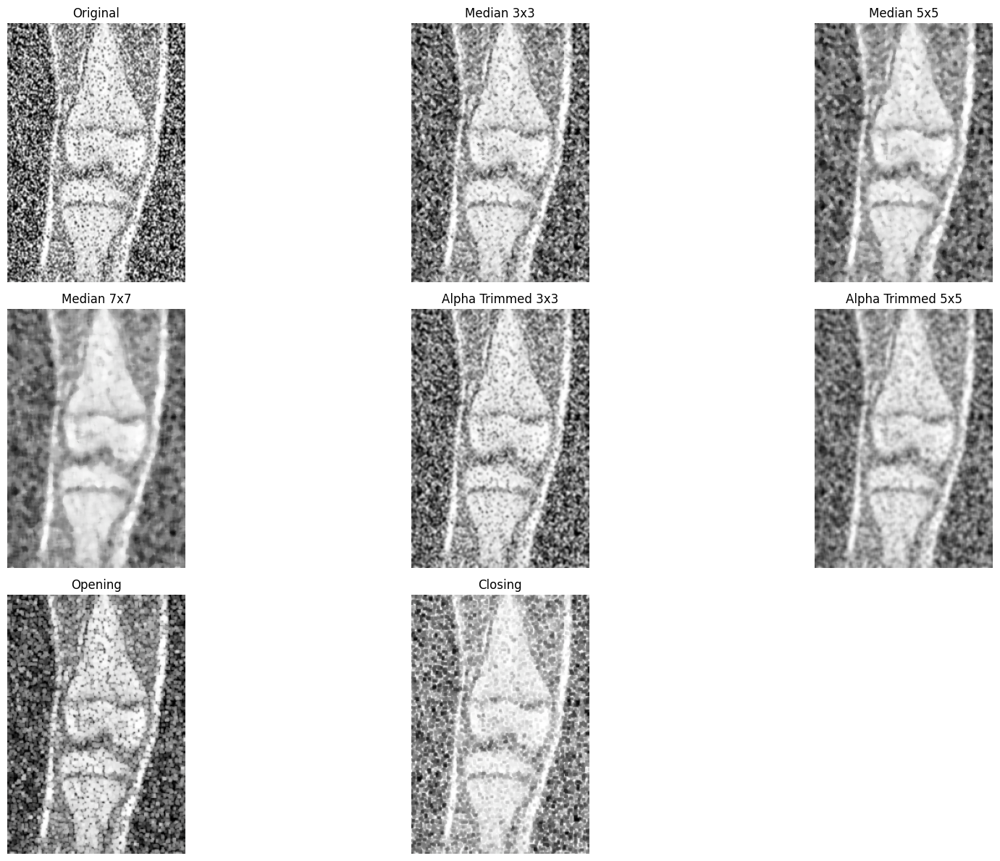

In [ ]:
results = {
    "Original": img,
    "Median 3x3": median_3,
    "Median 5x5": median_5,
    "Median 7x7": median_7,
    "Alpha Trimmed 3x3": alpha_3,
    "Alpha Trimmed 5x5": alpha_5,
    "Opening": opening,
    "Closing": closing
}
plt.figure(figsize=(18, 12))
for i, (name, image) in enumerate(results.items()):
    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(name)
    plt.axis("off")
plt.tight_layout()
plt.show()

           Filter   Sharpness
         Original 5593.508735
       Median 3x3 2315.644792
       Median 5x5  630.510144
       Median 7x7  244.364097
Alpha Trimmed 3x3  967.485730
Alpha Trimmed 5x5  153.474481
          Opening 2734.652514
          Closing  889.419501


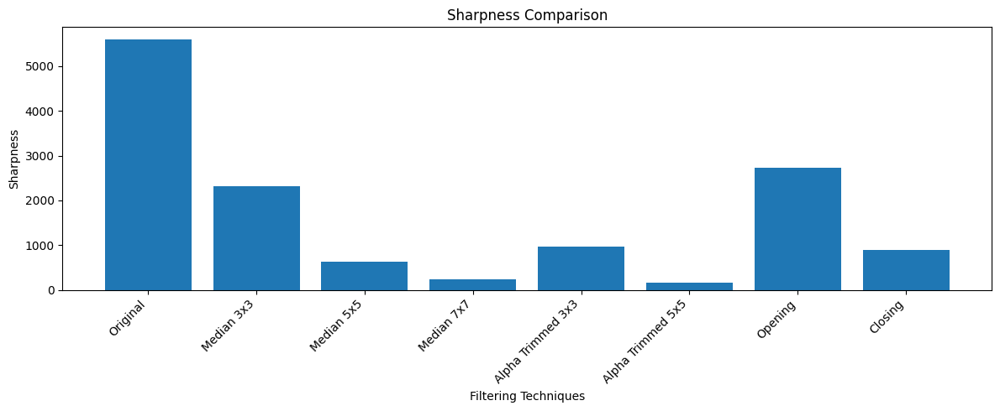

In [ ]:
sharpness_values = []
for name, image in results.items():
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    sharpness = cv2.Laplacian(
        gray,
        cv2.CV_64F
    ).var()
    sharpness_values.append([name, sharpness])
df = pd.DataFrame(
    sharpness_values,
    columns=["Filter", "Sharpness"]
)
print(df.to_string(index=False))
plt.figure(figsize=(12, 5))
plt.bar(df["Filter"], df["Sharpness"])
plt.xlabel("Filtering Techniques")
plt.ylabel("Sharpness")
plt.title("Sharpness Comparison")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

3.Image

Image loaded successfully
Image shape: (251, 497, 3)


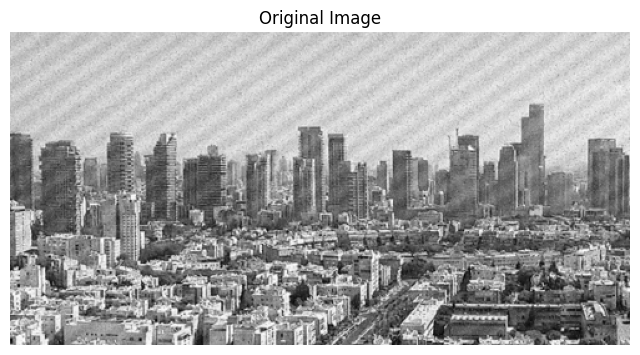

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import generic_filter

image_path = "/content/dp-3.png"

img = cv2.imread(image_path)

if img is None:
    raise ValueError("Image not found. Check the image path.")

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("Image loaded successfully")
print("Image shape:", img.shape)

plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.show()

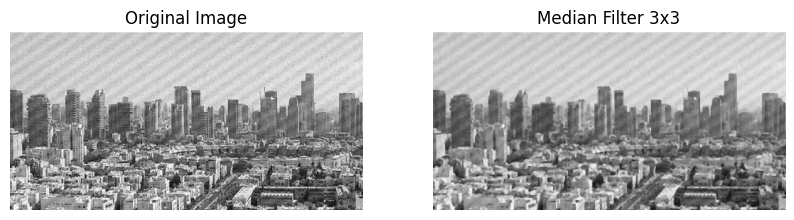

In [ ]:
median_3 = cv2.medianBlur(img, 3)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(median_3)
plt.title("Median Filter 3x3")
plt.axis("off")

plt.show()

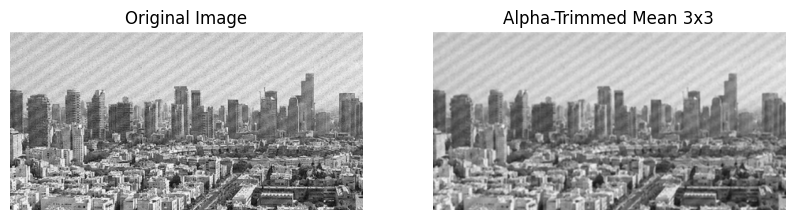

In [ ]:
def alpha_trimmed_filter(channel, size=3, d=2):

    def process(window):
        sorted_pixels = np.sort(window)
        trimmed = sorted_pixels[d//2:len(window)-d//2]
        return np.mean(trimmed)

    result = generic_filter(
        channel,
        process,
        size=size,
        mode="reflect"
    )

    return result.astype(np.uint8)


channels = []

for i in range(3):
    channels.append(
        alpha_trimmed_filter(img[:, :, i], 3, 2)
    )

alpha_3 = np.stack(channels, axis=2)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(alpha_3)
plt.title("Alpha-Trimmed Mean 3x3")
plt.axis("off")

plt.show()

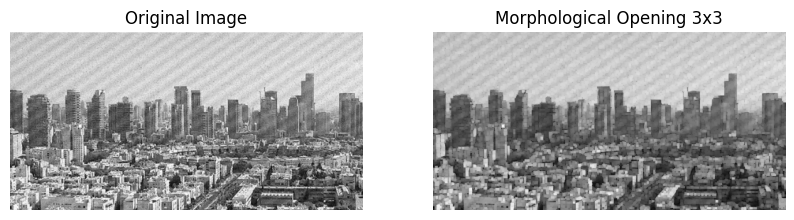

In [ ]:
kernel = np.ones((3, 3), np.uint8)

opening = cv2.morphologyEx(
    img,
    cv2.MORPH_OPEN,
    kernel
)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(opening)
plt.title("Morphological Opening 3x3")
plt.axis("off")

plt.show()

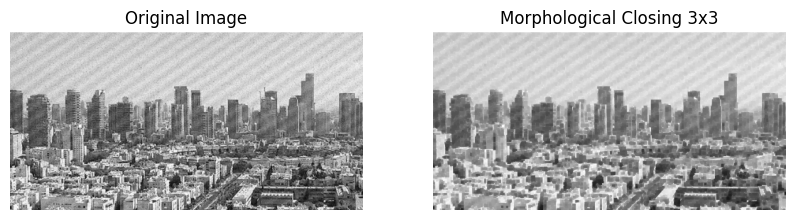

In [ ]:
kernel = np.ones((3, 3), np.uint8)

closing = cv2.morphologyEx(
    img,
    cv2.MORPH_CLOSE,
    kernel
)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(closing)
plt.title("Morphological Closing 3x3")
plt.axis("off")

plt.show()

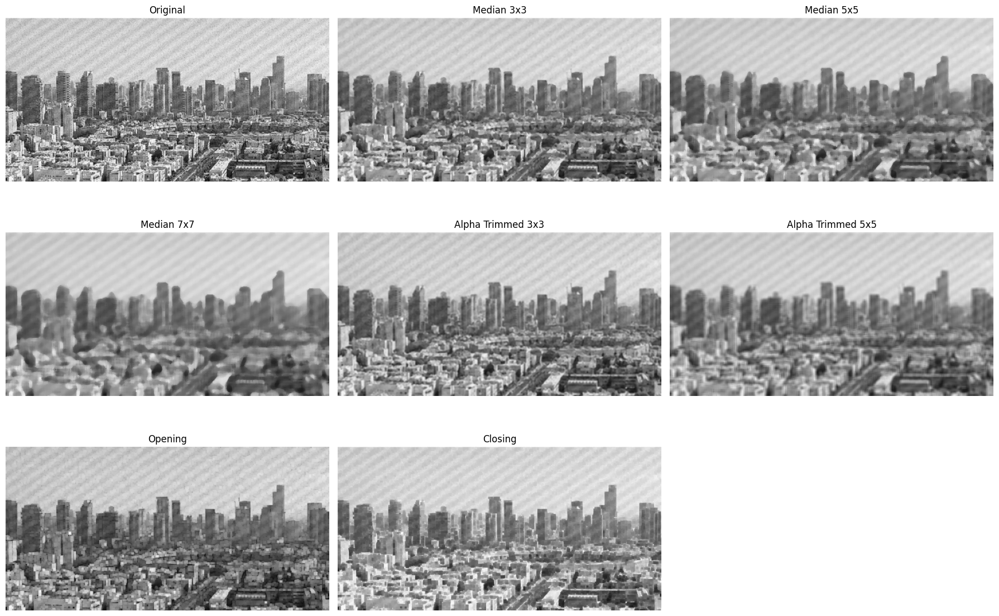

In [ ]:
results = {
    "Original": img,
    "Median 3x3": median_3,
    "Median 5x5": median_5,
    "Median 7x7": median_7,
    "Alpha Trimmed 3x3": alpha_3,
    "Alpha Trimmed 5x5": alpha_5,
    "Opening": opening,
    "Closing": closing
}
plt.figure(figsize=(18, 12))
for i, (name, image) in enumerate(results.items()):
    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(name)
    plt.axis("off")
plt.tight_layout()
plt.show()

                Filter   Sharpness
        Original Image 3996.462560
            Median 3x3  920.171958
            Median 5x5  332.235776
Alpha-Trimmed Mean 3x3  313.499019
 Morphological Opening 1217.402194
 Morphological Closing 1326.235165


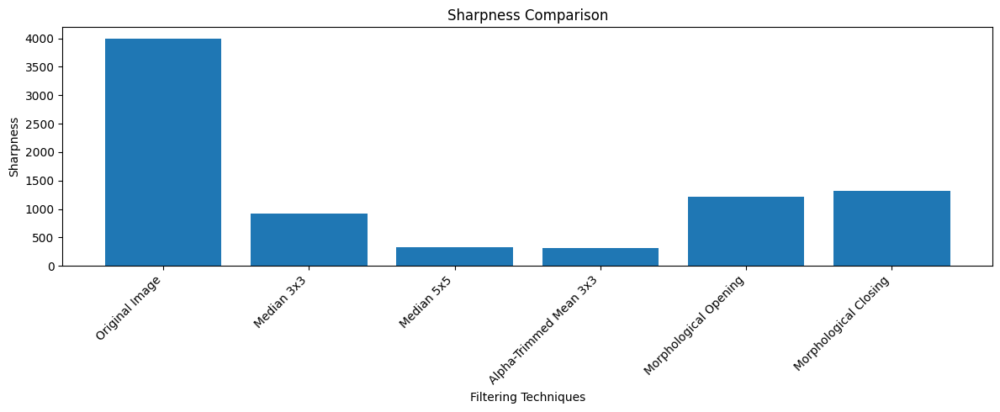

In [ ]:
import pandas as pd
import cv2
import matplotlib.pyplot as plt

sharpness_values = []
for name, image in results.items():
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    sharpness = cv2.Laplacian(
        gray,
        cv2.CV_64F
    ).var()
    sharpness_values.append([name, sharpness])
df = pd.DataFrame(
    sharpness_values,
    columns=["Filter", "Sharpness"]
)
print(df.to_string(index=False))
plt.figure(figsize=(12, 5))
plt.bar(df["Filter"], df["Sharpness"])
plt.xlabel("Filtering Techniques")
plt.ylabel("Sharpness")
plt.title("Sharpness Comparison")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

4 Image

Image loaded successfully
Image shape: (242, 507, 3)


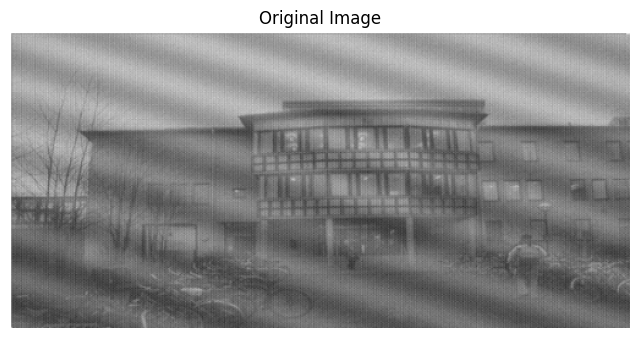

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.ndimage import generic_filter
image_path = "/content/Dsip image-4.png"
img = cv2.imread(image_path)
if img is None:
    raise ValueError("Image not found. Check the image path.")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
print("Image loaded successfully")
print("Image shape:", img.shape)
plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [ ]:
median_3 = cv2.medianBlur(img, 3)
median_5 = cv2.medianBlur(img, 5)
median_7 = cv2.medianBlur(img, 7)
plt.figure(figsize=(16, 10))
plt.subplot(2, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.subplot(2, 2, 2)
plt.imshow(median_3)
plt.title("Median Filter 3x3")
plt.axis("off")
plt.subplot(2, 2, 3)
plt.imshow(median_5)
plt.title("Median Filter 5x5")
plt.axis("off")
plt.subplot(2, 2, 4)
plt.imshow(median_7)
plt.title("Median Filter 7x7")
plt.axis("off")
plt.tight_layout()
plt.show()

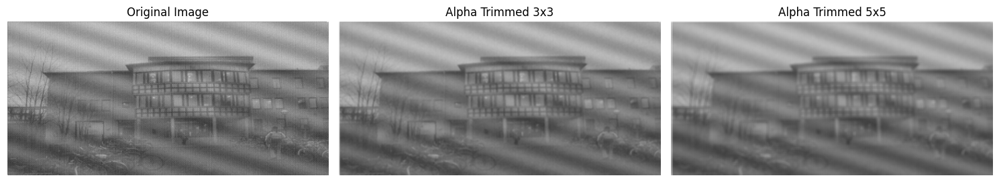

In [7]:
def alpha_trimmed_filter(channel, size=3, d=2):
    def process(window):
        sorted_pixels = np.sort(window)
        trimmed = sorted_pixels[d//2:len(window)-d//2]
        return np.mean(trimmed)
    result = generic_filter(
        channel,
        process,
        size=size,
        mode="reflect"
    )
    return result.astype(np.uint8)
def alpha_color(image, size=3, d=2):
    channels = []
    for i in range(3):
        channels.append(
            alpha_trimmed_filter(image[:, :, i], size, d)
        )
    return np.stack(channels, axis=2)
alpha_3 = alpha_color(img, 3, 2)
alpha_5 = alpha_color(img, 5, 2)
plt.figure(figsize=(15, 6))
plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(alpha_3)
plt.title("Alpha Trimmed 3x3")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(alpha_5)
plt.title("Alpha Trimmed 5x5")
plt.axis("off")
plt.tight_layout()
plt.show()

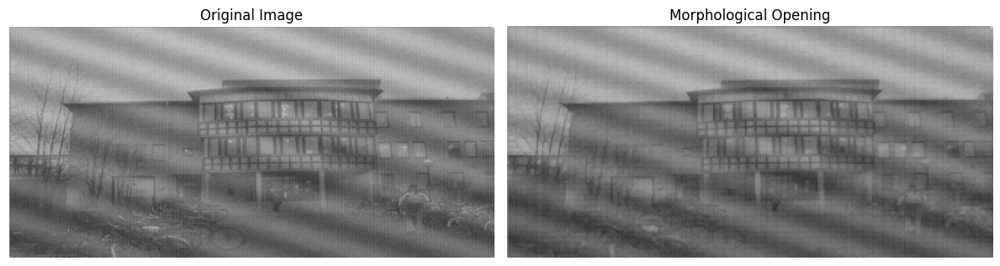

In [8]:
kernel = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(
    img,
    cv2.MORPH_OPEN,
    kernel
)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(opening)
plt.title("Morphological Opening")
plt.axis("off")
plt.tight_layout()
plt.show()

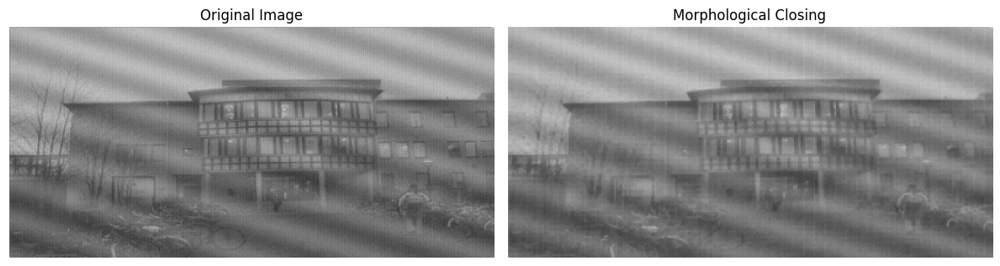

In [9]:
kernel = np.ones((3, 3), np.uint8)
closing = cv2.morphologyEx(
    img,
    cv2.MORPH_CLOSE,
    kernel
)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(closing)
plt.title("Morphological Closing")
plt.axis("off")
plt.tight_layout()
plt.show()

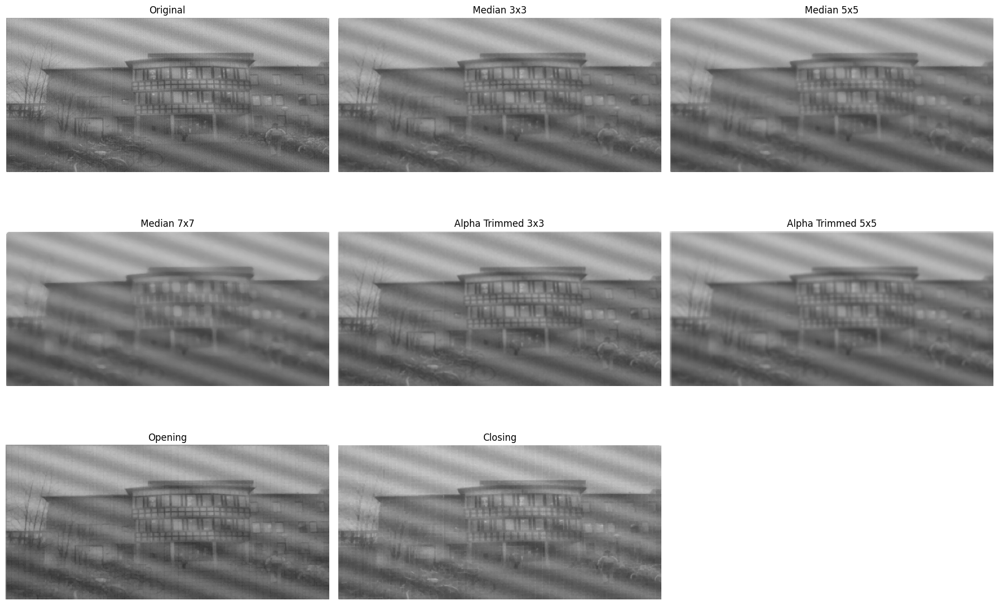

In [10]:
results = {
    "Original": img,
    "Median 3x3": median_3,
    "Median 5x5": median_5,
    "Median 7x7": median_7,
    "Alpha Trimmed 3x3": alpha_3,
    "Alpha Trimmed 5x5": alpha_5,
    "Opening": opening,
    "Closing": closing
}
plt.figure(figsize=(18, 12))
for i, (name, image) in enumerate(results.items()):
    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(name)
    plt.axis("off")
plt.tight_layout()
plt.show()

           Filter   Sharpness
         Original 1419.373346
       Median 3x3  407.524669
       Median 5x5  316.195183
       Median 7x7  286.710807
Alpha Trimmed 3x3  102.711261
Alpha Trimmed 5x5   20.261696
          Opening  154.171511
          Closing  424.785592


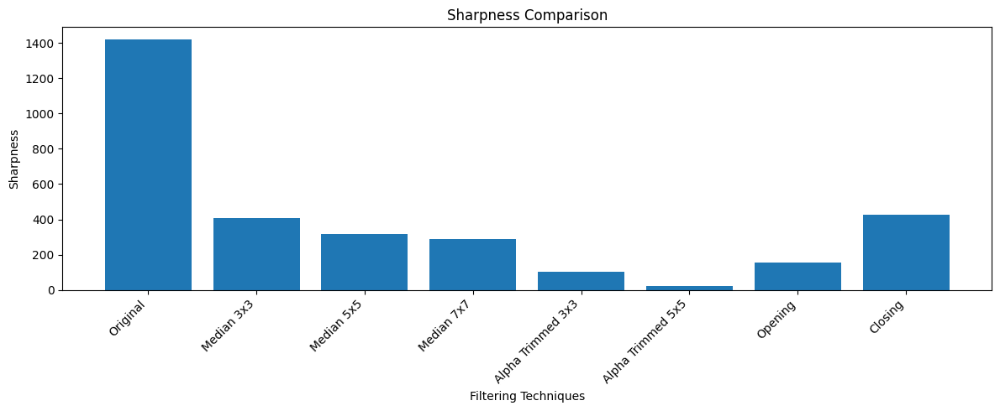

In [11]:
sharpness_values = []
for name, image in results.items():
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    sharpness = cv2.Laplacian(
        gray,
        cv2.CV_64F
    ).var()
    sharpness_values.append([name, sharpness])
df = pd.DataFrame(
    sharpness_values,
    columns=["Filter", "Sharpness"]
)
print(df.to_string(index=False))
plt.figure(figsize=(12, 5))
plt.bar(df["Filter"], df["Sharpness"])
plt.xlabel("Filtering Techniques")
plt.ylabel("Sharpness")
plt.title("Sharpness Comparison")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

5.image